# Tahap 06 — Hyperparameter Tuning

**Mini Project Machine Learning — Mobile Price Classification**

Sumber data: [Kaggle Mobile Price Classification](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification) (file `train.csv`, bukan `test.csv`).

**Lokasi dataset (VS Code)**: `P14/Mobile_Price_Classification/train.csv`. Di Google Colab: upload `train.csv` saat diminta.

**Penting:** notebook ini dapat dijalankan sendiri (tanpa modul Python proyek tambahan). Pilih kernel Python, lalu **Run All**, **Save** agar hasil grafik dan tabel terlihat di GitHub.


## 1. Import dan konfigurasi

In [1]:
"""Tahap 06 — Hyperparameter Tuning (mandiri).
Jalankan python 06_hyperparameter_tuning.py; notebook .ipynb memiliki fungsi yang sama.
Dataset: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification
"""
from __future__ import annotations

import json
import os
import sys
import time
from pathlib import Path
import hashlib

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.widgets import Button
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier



def find_project_root():
    """Works for .py from any CWD, VS Code notebooks, and Google Colab."""
    if "__file__" in globals():
        return Path(__file__).resolve().parent
    here = Path.cwd()
    candidates = (here, here / "P14", here.parent / "P14")
    for candidate in candidates:
        if (candidate / "Mobile_Price_Classification" / "train.csv").is_file():
            return candidate
        if (candidate / "train.csv").is_file():
            return candidate
    if (here / "P14").is_dir():
        return here / "P14"
    return here


def get_dataset_path():
    """train.csv must contain price_range (Kaggle test.csv has no labels)."""
    candidates = (
        BASE / "Mobile_Price_Classification" / "train.csv",
        BASE / "train.csv",
    )
    found = next((candidate for candidate in candidates if candidate.is_file()), None)
    if found is None and "google.colab" in sys.modules:
        from google.colab import files
        print("Upload train.csv (bukan test.csv) dari Kaggle Mobile Price Classification:")
        uploaded = files.upload()
        if "train.csv" not in uploaded:
            raise FileNotFoundError("Nama file yang di-upload harus train.csv")
        found = Path.cwd() / "train.csv"
    if found is None:
        raise FileNotFoundError(
            "train.csv tidak ditemukan. Simpan pada:\n"
            f"  {BASE / 'Mobile_Price_Classification' / 'train.csv'}\n"
            "atau (khusus notebook/Colab) pada folder kerja saat ini.\n"
            "Dataset: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification"
        )
    return found

BASE = find_project_root()
DATA_DIR = BASE / "Mobile_Price_Classification"
REPORT_DIR = BASE / "reports"
MODEL_DIR = BASE / "models"
FIGURE_DIR = BASE / "figures"
RANDOM_STATE = 42
TARGET = "price_range"

BASE_FEATURES = [
    "battery_power", "blue", "clock_speed", "dual_sim", "fc", "four_g",
    "int_memory", "m_dep", "mobile_wt", "n_cores", "pc", "px_height",
    "px_width", "ram", "sc_h", "sc_w", "talk_time", "three_g",
    "touch_screen", "wifi",
]
NEW_FEATURES = [
    "pixel_area", "screen_area", "battery_per_weight", "camera_total",
    "connectivity_count",
]
ALL_FEATURES = BASE_FEATURES + NEW_FEATURES
CLASS_LABELS = ["0 - Low", "1 - Medium", "2 - High", "3 - Very High"]
MODELS = {"Decision Tree": "decision_tree", "Random Forest": "random_forest", "SVM": "svm"}

## 2. Memuat dataset dan membagi train/test

In [2]:
def ensure_dirs():
    for directory in (REPORT_DIR, MODEL_DIR, FIGURE_DIR):
        directory.mkdir(parents=True, exist_ok=True)


def load_raw_dataset():
    path = get_dataset_path()
    frame = pd.read_csv(path)
    missing = [name for name in BASE_FEATURES + [TARGET] if name not in frame.columns]
    if missing:
        raise ValueError("Kolom dataset tidak lengkap: " + ", ".join(missing))
    if frame[TARGET].isna().any():
        raise ValueError("Target price_range memiliki missing value; periksa dataset")
    frame = frame[BASE_FEATURES + [TARGET]].copy()
    frame[TARGET] = pd.to_numeric(frame[TARGET], errors="raise").astype(int)
    if not set(frame[TARGET].unique()).issubset({0, 1, 2, 3}):
        raise ValueError("price_range harus berisi kelas 0, 1, 2, dan 3")
    for column in BASE_FEATURES:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


def load_split():
    """Use Stage 03 raw split, or recreate its exact deterministic split."""
    ensure_dirs()
    raw = load_raw_dataset()
    # Local P14: Stage 03 saved these CSVs. Colab without prior stages: regenerate.
    dataset_file = get_dataset_path()
    processed = dataset_file.parent / "processed"
    paths = {name: processed / f"{name}.csv" for name in ("X_train", "X_test", "y_train", "y_test")}
    if all(path.exists() for path in paths.values()):
        x_train = pd.read_csv(paths["X_train"])
        x_test = pd.read_csv(paths["X_test"])
        y_train = pd.read_csv(paths["y_train"])[TARGET]
        y_test = pd.read_csv(paths["y_test"])[TARGET]
        if (list(x_train.columns) == BASE_FEATURES and list(x_test.columns) == BASE_FEATURES
                and len(x_train) + len(x_test) == len(raw)
                and len(x_train) == len(y_train) and len(x_test) == len(y_test)):
            print("Menggunakan split Stage 03 dari:", processed)
            return x_train, x_test, y_train.astype(int), y_test.astype(int)
        print("Split Stage 03 tidak sesuai; membuat ulang split dari train.csv")
    x_train, x_test, y_train, y_test = train_test_split(
        raw[BASE_FEATURES], raw[TARGET], test_size=0.2, random_state=RANDOM_STATE,
        stratify=raw[TARGET],
    )
    processed.mkdir(parents=True, exist_ok=True)
    for name, part in {
        "X_train": x_train, "X_test": x_test,
        "y_train": y_train.to_frame(name=TARGET), "y_test": y_test.to_frame(name=TARGET),
    }.items():
        part.to_csv(paths[name], index=False)
    print("Split 80:20 dibuat dan disimpan:", processed)
    return x_train, x_test, y_train.astype(int), y_test.astype(int)

## 3. Feature engineering serta pipeline

In [3]:
class MobileFeatureEngineer(BaseEstimator, TransformerMixin):
    """Stateless, row-by-row construction; safe inside cross-validation pipelines."""

    def fit(self, X, y=None):
        self._validate(X)
        return self

    def _validate(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Model membutuhkan input DataFrame dengan nama 20 fitur asli")
        missing = set(BASE_FEATURES) - set(X.columns)
        if missing:
            raise ValueError("Input fitur tidak lengkap: " + ", ".join(sorted(missing)))

    def transform(self, X):
        self._validate(X)
        result = X[BASE_FEATURES].copy()
        for feature in BASE_FEATURES:
            result[feature] = pd.to_numeric(result[feature], errors="coerce")
        result["pixel_area"] = result["px_height"] * result["px_width"]
        result["screen_area"] = result["sc_h"] * result["sc_w"]
        result["battery_per_weight"] = result["battery_power"] / result["mobile_wt"].clip(lower=1)
        result["camera_total"] = result["fc"] + result["pc"]
        result["connectivity_count"] = result[["blue", "four_g", "three_g", "wifi"]].sum(axis=1, min_count=4)
        return result[ALL_FEATURES]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(ALL_FEATURES, dtype=object)


def cv_strategy():
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def model_pipeline(model_name):
    if model_name == "Decision Tree":
        estimator = DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE)
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=RANDOM_STATE)
    elif model_name == "SVM":
        estimator = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)
    else:
        raise ValueError("Algoritma tidak dikenal: " + model_name)
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if model_name == "SVM":
        numeric_steps.append(("scaler", StandardScaler()))
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), ALL_FEATURES),
    ], remainder="drop")
    # Fitur turunan dihitung secara deterministik sebelum CV.
    # Fitting imputer/scaler tetap di dalam Pipeline untuk mencegah leakage.
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])


def parameter_grid(model_name):
    quick = os.environ.get("P14_FAST_TEST") == "1"
    if model_name == "Decision Tree":
        return {"model__max_depth": [6] if quick else [5, 8, 10, None],
                "model__min_samples_leaf": [1] if quick else [1, 3]}
    if model_name == "Random Forest":
        return {"model__n_estimators": [20] if quick else [100, 150],
                "model__max_depth": [None] if quick else [None, 12],
                "model__min_samples_leaf": [1] if quick else [1, 3]}
    if model_name == "SVM":
        return {"model__C": [1] if quick else [0.5, 1, 5, 10],
                "model__gamma": ["scale"] if quick else ["scale", 0.01]}
    raise ValueError("Algoritma tidak dikenal: " + model_name)

## 4. Training & tuning (cross-validation)

In [4]:
def train_baselines():
    """Stage 05 results; evaluate by CV on training only."""
    ensure_dirs()
    csv_file = REPORT_DIR / "05_baseline_cv.csv"
    meta_file = REPORT_DIR / "05_baseline_metadata.json"
    fingerprint = hashlib.sha256(get_dataset_path().read_bytes()).hexdigest()
    expected_meta = {"code_version": "P14_FIXED_20261102_v3", "data_sha256": fingerprint}
    if (csv_file.exists() and meta_file.is_file()
            and all((MODEL_DIR / f"05_baseline_{slug}.joblib").is_file() for slug in MODELS.values())):
        try:
            if json.loads(meta_file.read_text(encoding="utf-8")) == expected_meta:
                print("Hasil baseline tahap 05 sudah valid; memakai hasil yang tersimpan.")
                return pd.read_csv(csv_file)
        except (ValueError, OSError):
            pass
    X_train, _, y_train, _ = load_split()
    X_train = MobileFeatureEngineer().fit_transform(X_train)
    records = []
    for name, slug in MODELS.items():
        print(f"Baseline CV 5-fold: {name}")
        model = model_pipeline(name)
        scores = cross_validate(
            model, X_train, y_train, cv=cv_strategy(),
            scoring={"f1_macro": "f1_macro", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
            n_jobs=1, error_score="raise", return_train_score=False,
        )
        record = {"model": name,
                  "f1_macro_cv_mean": float(scores["test_f1_macro"].mean()),
                  "f1_macro_cv_std": float(scores["test_f1_macro"].std()),
                  "accuracy_cv_mean": float(scores["test_accuracy"].mean()),
                  "balanced_accuracy_cv_mean": float(scores["test_balanced_accuracy"].mean()),
                  "fit_seconds_mean": float(scores["fit_time"].mean())}
        for i, value in enumerate(scores["test_f1_macro"], 1):
            record[f"f1_fold_{i}"] = float(value)
        model.fit(X_train, y_train)
        joblib.dump(model, MODEL_DIR / f"05_baseline_{slug}.joblib")
        records.append(record)
    table = pd.DataFrame(records).sort_values("f1_macro_cv_mean", ascending=False)
    table.to_csv(csv_file, index=False)
    meta_file.write_text(json.dumps(expected_meta, indent=2), encoding="utf-8")
    return table


def tune_models():
    """Stage 06: GridSearchCV on training only; never inspect held-out test."""
    ensure_dirs()
    csv_file = REPORT_DIR / "06_tuned_cv.csv"
    meta_file = REPORT_DIR / "06_tuned_metadata.json"
    fingerprint = hashlib.sha256(get_dataset_path().read_bytes()).hexdigest()
    expected_meta = {"code_version": "P14_FIXED_20261102_v3", "data_sha256": fingerprint,
                     "fast_test": os.environ.get("P14_FAST_TEST") == "1"}
    if (csv_file.exists() and meta_file.is_file()
            and all((MODEL_DIR / f"06_tuned_{slug}.joblib").is_file() for slug in MODELS.values())):
        try:
            if json.loads(meta_file.read_text(encoding="utf-8")) == expected_meta:
                print("Model tuning tahap 06 sudah valid; memakai hasil yang tersimpan.")
                return pd.read_csv(csv_file)
        except (ValueError, OSError):
            pass
    X_train, _, y_train, _ = load_split()
    X_train = MobileFeatureEngineer().fit_transform(X_train)
    records = []
    for name, slug in MODELS.items():
        print(f"GridSearchCV 5-fold: {name}", flush=True)
        search = GridSearchCV(
            estimator=model_pipeline(name), param_grid=parameter_grid(name),
            scoring={"f1_macro": "f1_macro", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
            refit="f1_macro", cv=cv_strategy(), n_jobs=1, error_score="raise",
            return_train_score=False,
        )
        started = time.perf_counter()
        search.fit(X_train, y_train)
        duration = time.perf_counter() - started
        best = search.best_index_
        record = {"model": name,
                  "f1_macro_cv_mean": float(search.cv_results_["mean_test_f1_macro"][best]),
                  "f1_macro_cv_std": float(search.cv_results_["std_test_f1_macro"][best]),
                  "accuracy_cv_mean": float(search.cv_results_["mean_test_accuracy"][best]),
                  "balanced_accuracy_cv_mean": float(search.cv_results_["mean_test_balanced_accuracy"][best]),
                  "fit_seconds_mean": float(search.cv_results_["mean_fit_time"][best]),
                  "total_search_seconds": duration,
                  "best_params": json.dumps(search.best_params_, ensure_ascii=True),
                  "n_candidates": len(search.cv_results_["params"])}
        records.append(record)
        joblib.dump(search.best_estimator_, MODEL_DIR / f"06_tuned_{slug}.joblib")
        details = pd.DataFrame(search.cv_results_)
        keep = [k for k in details.columns if k.startswith("param_") or k in (
            "mean_test_f1_macro", "std_test_f1_macro", "mean_test_accuracy", "rank_test_f1_macro")]
        details[keep].sort_values("rank_test_f1_macro").to_csv(REPORT_DIR / f"06_grid_{slug}.csv", index=False)
        print(f"  -> F1 macro CV = {record['f1_macro_cv_mean']:.4f}; params = {search.best_params_}")
    table = pd.DataFrame(records).sort_values("f1_macro_cv_mean", ascending=False)
    table.to_csv(csv_file, index=False)
    meta_file.write_text(json.dumps(expected_meta, indent=2), encoding="utf-8")
    return table

## 5. Utilitas grafik dan tabel

In [5]:
def save_figure(figure, stage, filename, paths):
    folder = FIGURE_DIR / stage
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / filename
    figure.savefig(path, bbox_inches="tight", dpi=150)
    plt.close(figure)
    paths.append(path)
    return path


def view_gallery(image_paths):
    if not image_paths:
        return
    if "google.colab" in sys.modules or "ipykernel" in sys.modules:
        from IPython.display import display, Image
        for p in image_paths:
            print(p.name)
            display(Image(filename=str(p)))
        return
    if os.environ.get("P14_NO_GUI") == "1" or matplotlib.get_backend().lower() == "agg":
        print(f"Grafik tersimpan ({len(image_paths)} PNG). Tidak membuka window pada mode tanpa GUI.")
        return
    index = [0]
    fig, ax = plt.subplots(figsize=(11, 7))
    fig.subplots_adjust(bottom=0.17, top=0.91)
    ax.set_axis_off()
    first = plt.imread(image_paths[0])
    image = ax.imshow(first, interpolation="nearest")
    ax.set_xlim(0, first.shape[1])
    ax.set_ylim(first.shape[0], 0)
    title = ax.set_title(f"1/{len(image_paths)} - {image_paths[0].stem}")
    prev_axis = fig.add_axes((0.32, 0.045, 0.15, 0.065))
    next_axis = fig.add_axes((0.53, 0.045, 0.15, 0.065))
    previous = Button(prev_axis, "Previous")
    following = Button(next_axis, "Next")

    def move(by):
        index[0] = (index[0] + by) % len(image_paths)
        pixels = plt.imread(image_paths[index[0]])
        image.set_data(pixels)
        image.set_extent((0, pixels.shape[1], pixels.shape[0], 0))
        ax.set_xlim(0, pixels.shape[1])
        ax.set_ylim(pixels.shape[0], 0)
        title.set_text(f"{index[0]+1}/{len(image_paths)} - {image_paths[index[0]].stem}")
        fig.canvas.draw_idle()

    previous.on_clicked(lambda event: move(-1))
    following.on_clicked(lambda event: move(1))
    fig.canvas.mpl_connect("key_press_event", lambda event: move(-1) if event.key == "left" else (move(1) if event.key == "right" else None))
    print("Navigasi: klik Previous/Next atau gunakan tombol panah kiri/kanan.")
    plt.show()


def cli_summary(table, digits=4):
    with pd.option_context("display.max_columns", 12, "display.width", 125, "display.float_format", f"{{:.{digits}f}}".format):
        print(table.to_string(index=False))

## 6. Hasil tahap ini

In [6]:
# ==================== KODE TAHAP 06 ====================


"""Tahap 06: GridSearchCV 5-fold untuk ketiga algoritma, scoring=f1_macro.

Pilih hyperparameter dari TRAIN saja. Prediksi test belum dihitung.
"""

import numpy as np
import matplotlib.pyplot as plt



def main():
    baseline = train_baselines()
    tuned = tune_models()
    print("\n=== 06 HASIL GRIDSEARCHCV ===")
    cli_summary(tuned[["model", "f1_macro_cv_mean", "accuracy_cv_mean", "n_candidates", "total_search_seconds"]])
    for _, row in tuned.iterrows():
        print(f"{row['model']}: parameter terbaik = {row['best_params']}")
    print("\nParameter optimal dipilih dari CV training, bukan dari test set.")

    figures = []
    names = list(MODELS)
    baseline_scores = baseline.set_index("model").loc[names, "f1_macro_cv_mean"]
    tuned_scores = tuned.set_index("model").loc[names, "f1_macro_cv_mean"]
    x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x - 0.19, baseline_scores, width=0.38, label="Baseline")
    ax.bar(x + 0.19, tuned_scores, width=0.38, label="Setelah GridSearchCV")
    ax.set_xticks(x, names)
    ax.set(title="Baseline vs Tuning - F1 Macro CV", ylabel="Mean F1 Macro CV", ylim=(0, 1.05))
    ax.legend()
    fig.tight_layout()
    save_figure(fig, "06_hyperparameter_tuning", "01_f1_sebelum_sesudah.png", figures)

    for name, slug in MODELS.items():
        candidate = REPORT_DIR / f"06_grid_{slug}.csv"
        import pandas as pd
        df = pd.read_csv(candidate).sort_values("rank_test_f1_macro").head(8)
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.barh([f"Kandidat {int(r)}" for r in df["rank_test_f1_macro"].iloc[::-1]], df["mean_test_f1_macro"].iloc[::-1])
        ax.set(title=f"8 Kombinasi Terbaik: {name}", xlabel="F1 Macro CV")
        ax.set_xlim(0, 1.05)
        fig.tight_layout()
        save_figure(fig, "06_hyperparameter_tuning", f"02_kandidat_{slug}.png", figures)

    print("\nOutput hasil tuning:", REPORT_DIR / "06_tuned_cv.csv")
    view_gallery(figures)

## Jalankan tahap

Hasil baseline tahap 05 sudah valid; memakai hasil yang tersimpan.
Menggunakan split Stage 03 dari: C:\Github\Tugas_Machine_Learning_Semester_6\P14\Mobile_Price_Classification\processed
GridSearchCV 5-fold: Decision Tree


  -> F1 macro CV = 0.8359; params = {'model__max_depth': None, 'model__min_samples_leaf': 3}
GridSearchCV 5-fold: Random Forest


  -> F1 macro CV = 0.8858; params = {'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__n_estimators': 150}
GridSearchCV 5-fold: SVM


  -> F1 macro CV = 0.8983; params = {'model__C': 5, 'model__gamma': 0.01}

=== 06 HASIL GRIDSEARCHCV ===
        model  f1_macro_cv_mean  accuracy_cv_mean  n_candidates  total_search_seconds
          SVM            0.8983            0.8981             8                9.6672
Random Forest            0.8858            0.8863             8               30.4546
Decision Tree            0.8359            0.8363             8                1.8160
SVM: parameter terbaik = {"model__C": 5, "model__gamma": 0.01}
Random Forest: parameter terbaik = {"model__max_depth": 12, "model__min_samples_leaf": 1, "model__n_estimators": 150}
Decision Tree: parameter terbaik = {"model__max_depth": null, "model__min_samples_leaf": 3}

Parameter optimal dipilih dari CV training, bukan dari test set.



Output hasil tuning: C:\Github\Tugas_Machine_Learning_Semester_6\P14\reports\06_tuned_cv.csv
01_f1_sebelum_sesudah.png


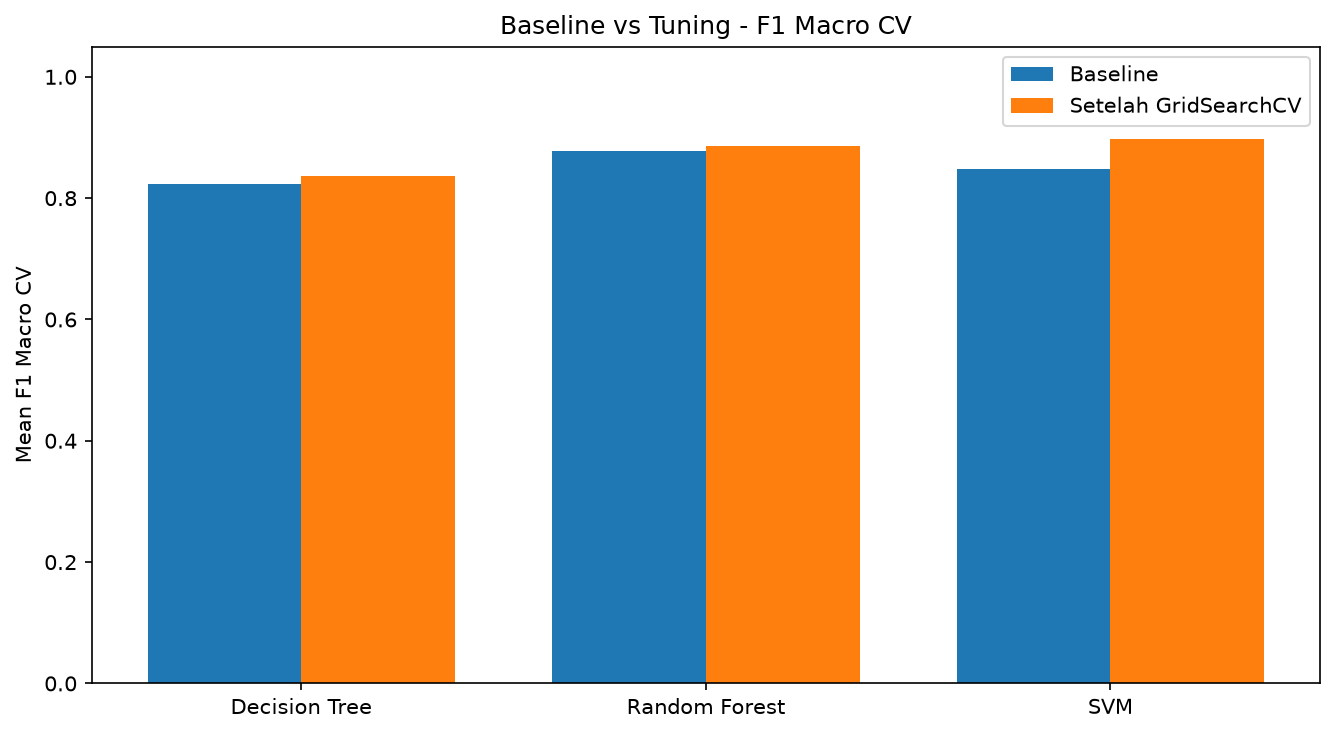

02_kandidat_decision_tree.png


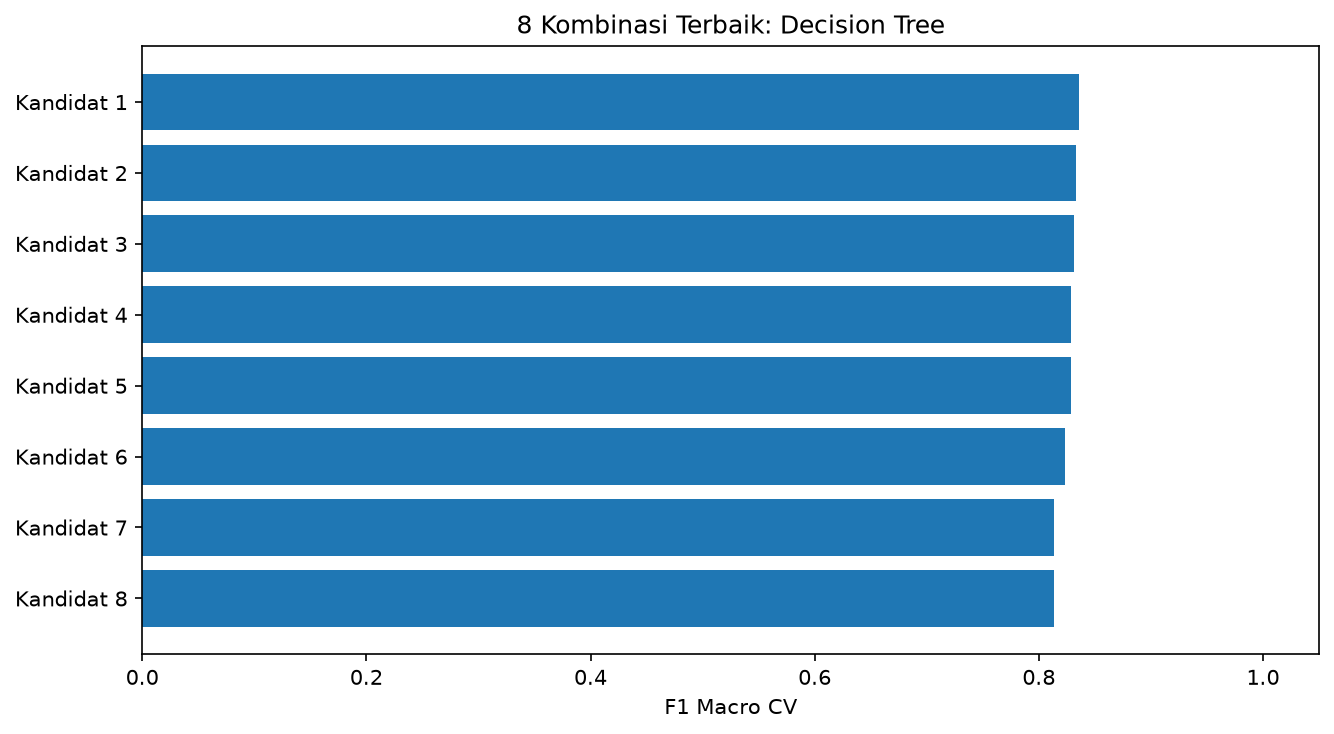

02_kandidat_random_forest.png


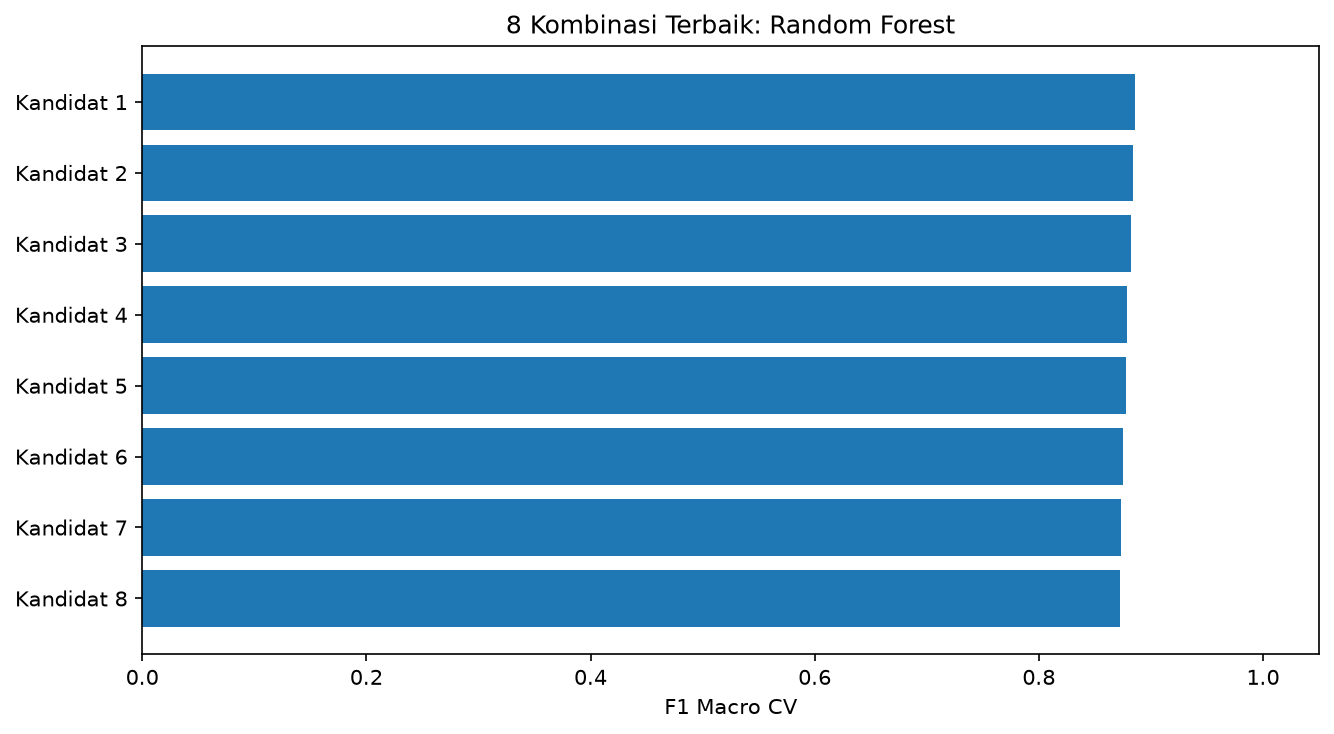

02_kandidat_svm.png


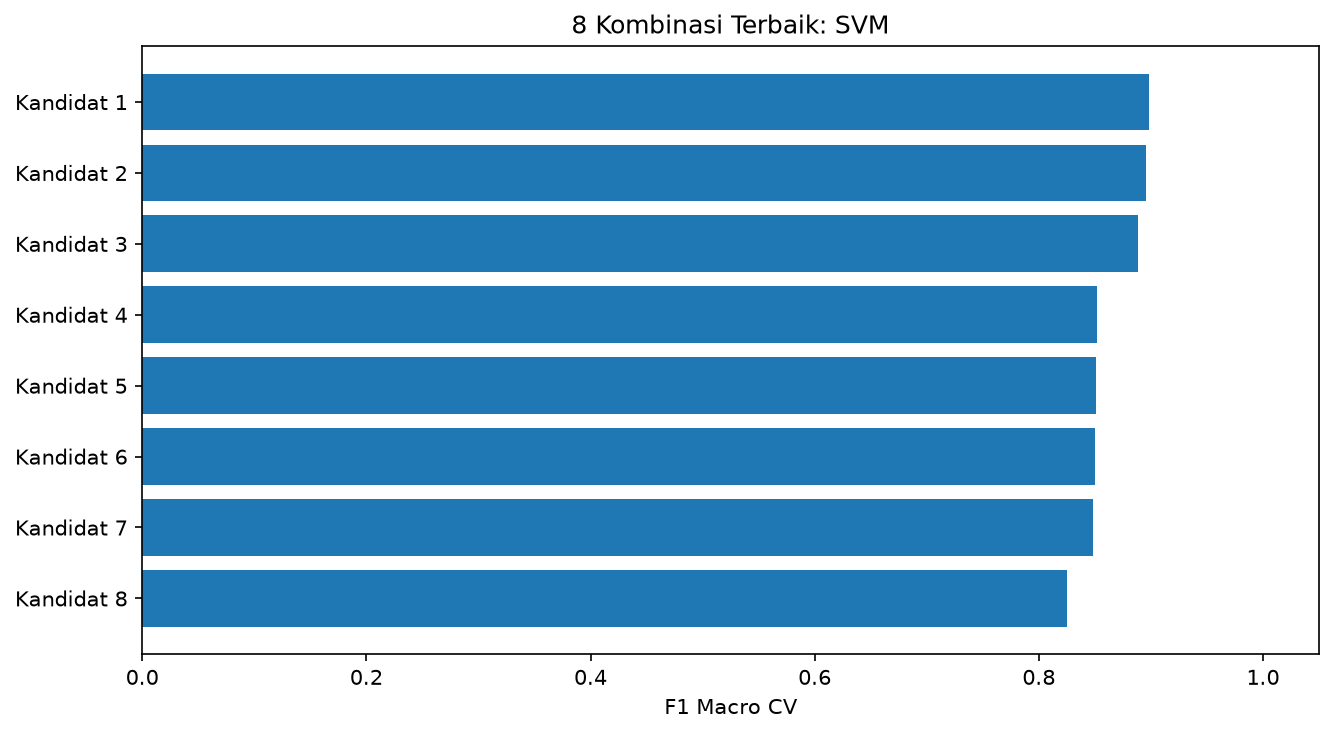

In [7]:
main()